<a href="https://colab.research.google.com/github/bramhani007/192425319-MLA0204/blob/main/Practical_Problem_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving customer_segments.csv to customer_segments.csv
DATASET:
    Monthly_Income  Spending_Score
0               20              25
1               22              30
2               25              28
3               28              35
4               30              40
5               32              38
6               35              45
7               40              50
8               65              68
9               70              75
10              75              80
11              78              72
12              82              85
13              85              90
14              88              82
15              90              95

Expectation Maximization Results:
    Monthly_Income  Spending_Score  Cluster
0               20              25        0
1               22              30        0
2               25              28        0
3               28              35        0
4               30              40        0
5               32              38        0

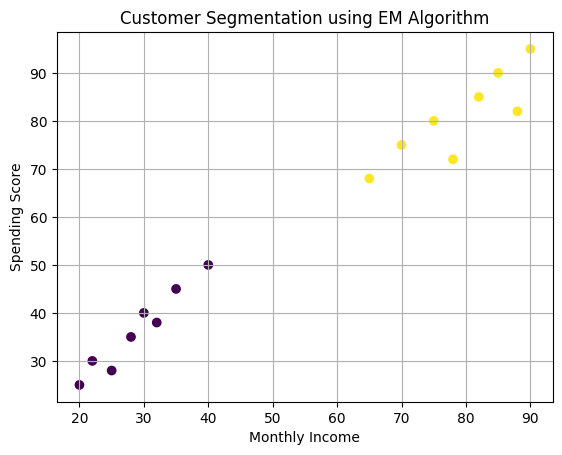

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))
data = pd.read_csv(io.BytesIO(uploaded[filename]))

print("DATASET:")
print(data)

# Select input features
X = data[["Monthly_Income", "Spending_Score"]]

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create Gaussian Mixture Model
model = GaussianMixture(
    n_components=2,
    random_state=42,
    n_init=5
)

# Train using EM algorithm
model.fit(X_scaled)

# Predict clusters
clusters = model.predict(X_scaled)

# Add cluster column
data["Cluster"] = clusters

print("\nExpectation Maximization Results:")
print(data)

print("\nCluster Means:")
print(model.means_)

print("\nNumber of Iterations:")
print(model.n_iter_)

print("\nConverged:")
print(model.converged_)

# Plot clusters
plt.scatter(
    data["Monthly_Income"],
    data["Spending_Score"],
    c=clusters
)

plt.xlabel("Monthly Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using EM Algorithm")
plt.grid()
plt.show()